In [1]:
import numpy as np 
import xarray as xr

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

import time
start_time = time.time()

In [2]:
%cd /emmy-noether/home/mf671/DATA/ERA5/geop
#!cdo -selmon,6,7,8 ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023.nc
#!ls

/emmy-noether/home/mf671/DATA/ERA5/geop


In [3]:
print("Starting operation")

'''
data_dir='/emmy-noether/home/mf671/DATA/ERA5/geop/'
fn = data_dir + "ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc"
work_dic='/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/'
fn_out_unfilt = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_tyrlis_EW.nc"
fn_out = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW.nc"
fn_dic_unfilt = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_DIC_tyrlis_EW.npy"
fn_dic = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC_tyrlis_EW.npy"
'''
data_dir='/emmy-noether/home/mf671/DATA/ERA5/geop/'
fn = data_dir + "ERA5_northem_2.5x2.5_zg500_daily_1960-1963.nc"
work_dic='/emmy-noether/home/mf671/DATA/ERA5/gr_tracking/'
fn_out_unfilt = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc"
fn_out = work_dic + "ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc"
fn_dic_unfilt = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963_DIC.npy"
fn_dic = work_dic + "dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963_DIC.npy"
#'''

Starting operation


In [4]:
ds = xr.load_dataset(fn)
print("Data correctly read")
ds = BT.DAV(ds,mer_gradient_filter = True, tyrlis_correction=True)
#ds = BT.DAV(ds)
print(np.amax(ds['DAV_freq']))
print("DAV function correctly executed")
ds,dic_unfilt = BT.ContourTracking2D(ds,var_name = "DAV")
#saving temporary data
ds.to_netcdf(fn_out_unfilt)
np.save(fn_dic_unfilt,dic_unfilt)

Data correctly read
__Starting a DAV process__
input: zg500 , mer_gradient_filter = True, tyrlis_correction = True
<xarray.DataArray 'DAV_freq' ()> Size: 8B
array(25.11978097)
DAV function correctly executed
__Starting a Tracking process__
input: DAV
connected component analysis


100%|██████████████████████████████████████████████████████████████████| 1461/1461 [00:03<00:00, 371.13it/s]


rearranging indexes


100%|█████████████████████████████████████████████████████████████████| 1461/1461 [00:00<00:00, 2530.95it/s]


calculating characteristics
persistence, track, date:


100%|██████████████████████████████████████████████████████████████████| 1461/1461 [00:11<00:00, 128.12it/s]


area, WBI and intensity


100%|███████████████████████████████████████████████████████████████████| 1461/1461 [00:54<00:00, 27.05it/s]


number of labels: 4414.0


In [5]:
from importlib import reload
reload(BT)
ds = xr.load_dataset(fn_out_unfilt)
dic_unfilt = np.load(fn_dic_unfilt,allow_pickle=True)
ds2,dic_filt = BT.FilterEvents(ds,dic_unfilt,var_name = "DAV",
                              pers_min = 5,min_avg_area = 5e5)
print("ContourTracking2D function correclty executed")

__Starting a Filtering process__
input: DAV_tracked
applying filters


100%|████████████████████████████████████████████████████████████████| 4414/4414 [00:00<00:00, 58348.41it/s]


rearranging indexes


100%|████████████████████████████████████████████████████████████████| 1461/1461 [00:00<00:00, 17900.29it/s]

number of labels: 262


ContourTracking2D function correclty executed


In [6]:
#saving data
np.save(fn_dic,dic_filt)
ds2.to_netcdf(fn_out)
print("Data created")
  
print("--- %s seconds ---" % (time.time() - start_time))

Data created
--- 76.93817400932312 seconds ---


In [7]:
zg1d = ds['zg'].loc[:,45,-20]

In [8]:
zg1d_seasonal_mean = zg1d.groupby('time.month').mean(dim='time')

In [9]:
zg1d_mean = zg1d.mean(dim='time')

In [10]:
zg1d_deseasonalized = zg1d.groupby('time.month') - zg1d_seasonal_mean + zg1d_mean

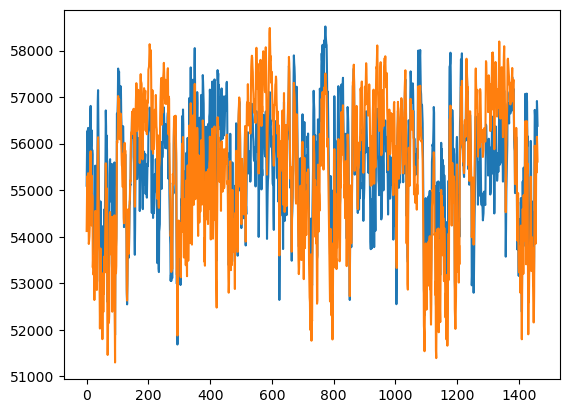

In [11]:
import matplotlib.pyplot as plt
plt.plot(zg1d_deseasonalized)
plt.plot(zg1d)

In [12]:
label = 20
print(dic_filt[label])
print(sum(dic_filt[label]['WBI'])/len(dic_filt[label]['WBI']))

{'persistence': 5, 'area': [np.float64(510542.58064779954), np.float64(1132677.5449690244), np.float64(1349360.5829419855), np.float64(1750429.8567266106), np.float64(1233592.4502477378)], 'distance_traveled': [np.float64(417.9955424468177), np.float64(236.2525351643656), np.float64(63.54391450375579), np.float64(297.61435045948537)], 'track': [[np.float64(48.75), np.float64(52.39583333333333), np.float64(53.01724137931035), np.float64(53.421052631578945), np.float64(55.267857142857146)], [np.float64(5.0), np.float64(6.5625), np.float64(9.913793103448285), np.float64(10.592105263157919), np.float64(13.928571428571416)]], 'date': np.datetime64('1960-05-04T06:00:00.000000000'), 'intensity': [np.float64(-4.123388671875), np.float64(55.7642822265625), np.float64(82.52074353448276), np.float64(85.20500102796052), np.float64(92.6434326171875)], 'WBI': [np.float64(-0.07945318222045898), np.float64(-4.411123275756836), np.float64(-2.6696669479896284), np.float64(-3.651120236045436), np.float64

In [13]:
WBIS = []
INTENSITIES = []
XS = []
YS = []

for event in dic_filt[1:]:
    for i in range(event['persistence']):
        WBIS.append(sum(event['WBI'])/len(event['WBI']))
        INTENSITIES.append(event['intensity'][i])
        XS.append(event['track'][0][i])
        YS.append(event['track'][1][i])

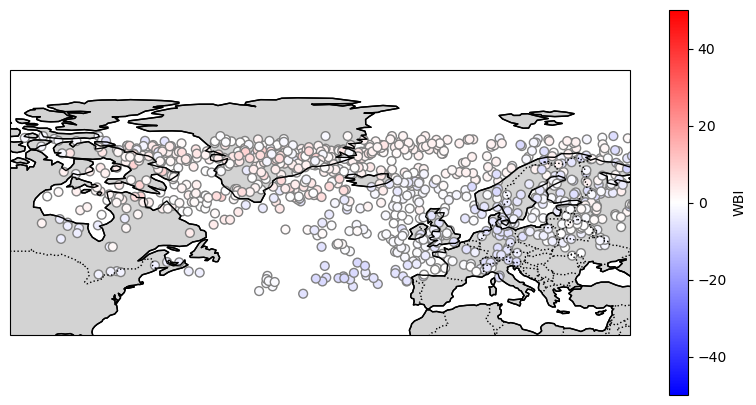

In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  XS # Example latitudes
lons = YS#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = WBIS#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = -50 #Plot the scatter points with color mapping
vmax = 50
sc = ax.scatter(lons, lats, c=values, cmap='bwr', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='WBI')

# Show the plot
plt.show()


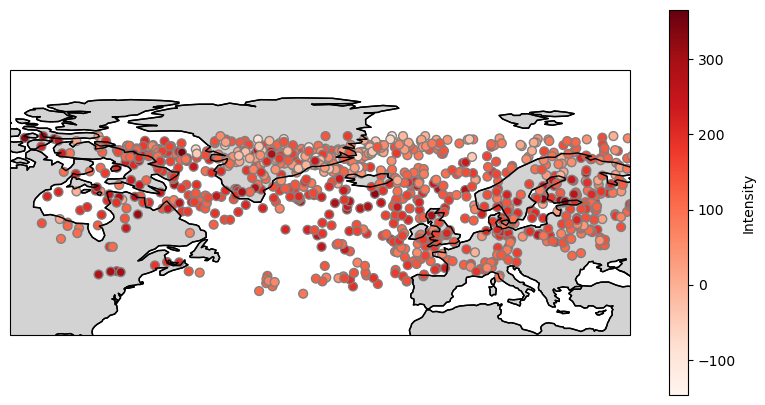

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  XS # Example latitudes
lons = YS#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INTENSITIES#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
vmin = np.amin(np.array(values)) #Plot the scatter points with color mapping
vmax = np.amax(np.array(values))
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='Intensity')

# Show the plot
plt.show()


In [16]:
percentile_90 = np.percentile(INTENSITIES, 90)

In [17]:
WBIS_max = []
INTENSITIES_max = []
XS_max = []
YS_max = []

for i,intensity in enumerate(INTENSITIES):
    if intensity > percentile_90:
        WBIS_max.append(WBIS[i])
        INTENSITIES_max.append(INTENSITIES[i])
        XS_max.append(XS[i])
        YS_max.append(YS[i])

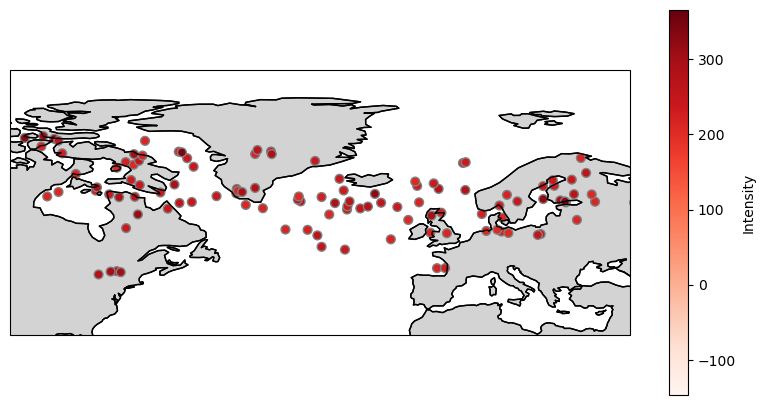

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Sample data: latitudes, longitudes, and a float value for color mapping
lats =  XS_max # Example latitudes
lons = YS_max#[-118.25, -74.01, -0.12, 151.21, 139.69]  # Example longitudes
values = INTENSITIES_max#[10, 20, 30, 40, 50]  # Float values for coloring

# Create figure and axis with a projection
fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={'projection': ccrs.PlateCarree()})

# Add map features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.LAND, edgecolor='black', facecolor='lightgray')
ax.set_extent((-100,40,30,90))
#vmin = np.amin(np.array(values)) #Plot the scatter points with color mapping
#vmax = np.amax(np.array(values))
sc = ax.scatter(lons, lats, c=values, cmap='Reds', vmin=vmin, vmax=vmax ,edgecolors='grey',s=40, transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation='vertical', label='Intensity')

# Show the plot
plt.show()
